# Bước 0 - Kiểm bộ nạp để sẵn dữ liệu trên GPU (khóa data_on_gpu của fork, nhánh gpu-loader) trên Kaggle T4, dữ liệu thật, cấu hình B1b (Sequential Forecast LSTM có Q của BiasCast, qmean_mmd + qmax_mmd, hạt giống 111).
 Vì sao: notebook đo bộ nạp (Workspace/04_Setup/02_0_DataLoader_Benchmark/02_0_DataLoader_Benchmark.md, Version 1) cho
 thấy 56% thời gian một epoch là chờ hoặc đọc dữ liệu; bản thử để sẵn dữ liệu trên GPU ước rút một lần chạy từ 6,5 xuống
 2,4 giờ. Bản sửa thư viện đã đạt 17 kiểm thử trên CPU (test/test_gpu_loader.py, dữ liệu CAMELS-US của thư viện); notebook
 này kiểm trên đúng GPU, dữ liệu và cấu hình của B0 trước khi dùng.
 Cách kiểm: chế độ tất định của PyTorch, huấn luyện B1b 2 epoch rồi chấm test, 3 run chỉ khác bộ nạp:
   A  - bộ nạp cũ (data_on_gpu tắt), A2 - bộ nạp cũ lần hai (đo lệch tự nhiên giữa hai lần chạy), B - bộ nạp mới.
 Điều kiện đạt (ghi trước khi chạy), so trên: trọng số epoch 1, 2, loss từng bước huấn luyện, NSE/KGE validation và test
 từng lưu vực. Nếu A trùng A2 từng bit (chạy tất định) thì B phải trùng A từng bit; nếu không, lệch A-B không được lớn hơn lệch A-A2.
 Chế độ tất định chỉ dùng ở notebook này; B0 trở đi chạy như A4 (02_Pipeline.md Mục 5).
# Bài: Konold và cs., HESS 30:5067-5096 (2026). Dữ liệu Zenodo 17119635 (CC BY-NC 4.0), config tác giả Zenodo 17292895
      - đã lưu thành Kaggle Dataset "lamah-ce-ext" (Workspace/01_Download/01_LamaHCEExt_Download/01_LamaHCEExt_Download.py).
 Cài đặt notebook: Accelerator = GPU T4 (dùng GPU 0), Internet = On, Persistence = Files only,
 Add Input => lamah-ce-ext. Phiên tương tác: mỗi Phần một cell, chạy lần lượt; Phần 1 phải là cell đầu tiên của phiên
 (biến môi trường của cuBLAS chỉ có tác dụng khi đặt trước lúc CUDA khởi động).
 Bản chính thức: dán nguyên tệp (mỗi "# %% Phần" một cell) rồi Save & Run All, không sửa dòng nào.

# MỤC LỤC
   Phần 1 - Bật chế độ tất định, cài fork nhánh gpu-loader, kiểm mã đã cài, kiểm môi trường
   Phần 2 - Tìm dữ liệu, config tác giả, dựng thư mục dữ liệu có cột qmean_mmd, qmax_mmd
   Phần 3 - Config B1b 2 epoch cho 3 run: A, A2 (bộ nạp cũ), B (bộ nạp mới)
   Phần 4 - Run A: bộ nạp cũ, huấn luyện 2 epoch + validation, chấm test
   Phần 5 - Run A2: bộ nạp cũ lần hai (đo lệch tự nhiên giữa hai lần chạy giống hệt nhau)
   Phần 6 - Run B: bộ nạp mới (data_on_gpu True)
   Phần 7 - So 3 run: trọng số, loss từng bước, chỉ số từng lưu vực; thời gian từng epoch
   Phần 8 - Môi trường, danh mục tệp

Thư viện,Phiên bản,pip đổi?
neuralhydrology,1.12.0 (commit f229e02),
numpy,2.1.3,
pandas,2.3.3,
xarray,2025.12.0,
torch,2.11.0+cu128,
scipy,1.16.3,
numba,0.61.2,
ruamel.yaml,0.19.1,
matplotlib,3.10.0,
tensorboard,2.20.0,


Mục,Giá trị
Python,3.13.15
torch / CUDA của torch,2.11.0+cu128 / 12.8
cuDNN,91900
Số GPU,2
GPU,"0: Tesla T4 (cc 7.5, 14.6 GB); 1: Tesla T4 (cc 7.5, 14.6 GB)"
CPU,Intel(R) Xeon(R) CPU @ 2.00GHz
Số CPU (os.cpu_count / được dùng),4 / 4
RAM tổng / còn trống (GB),31.3 / 29.7
Đĩa trống ở WORK_DIR (GB),19.5
Ngày dựng ảnh Kaggle,20261022-041805


Tệp,Trùng từng byte
datautils/gpu_loader.py,ĐẠT
training/basetrainer.py,ĐẠT
evaluation/tester.py,ĐẠT
datasetzoo/basedataset.py,ĐẠT
utils/config.py,ĐẠT


Điều kiện,Đạt
Cài đúng commit f229e02 (nhánh gpu-loader),ĐẠT
pip không đổi thư viện có sẵn,ĐẠT
Có GPU T4,ĐẠT
Có tensorboard (training/logger.py nạp khi import),ĐẠT
Nạp gpu_loader,ĐẠT
Nạp basetrainer,ĐẠT
Nạp tester,ĐẠT
Nạp sequential_forecast_lstm,ĐẠT
5 tệp liên quan trùng commit,ĐẠT
Config có khóa data_on_gpu,ĐẠT


=> Đạt. Chạy Phần 2.


...

=> Xong run B. Chạy Phần 7.


mục,số phần tử,A-A2: khác / lệch lớn nhất,A-B: khác / lệch lớn nhất,A2-B: khác / lệch lớn nhất
trọng số epoch 1,"84,801",trùng,trùng,trùng
trọng số epoch 2,"84,801",trùng,trùng,trùng
loss từng bước,"8,550",trùng,trùng,trùng
NSE validation epoch 1,451,trùng,trùng,trùng
KGE validation epoch 1,451,trùng,trùng,trùng
NSE validation epoch 2,451,trùng,trùng,trùng
KGE validation epoch 2,451,trùng,trùng,trùng
NSE test epoch 2,451,trùng,trùng,trùng
KGE test epoch 2,451,trùng,trùng,trùng


mục,đạt
trọng số epoch 1,ĐẠT
trọng số epoch 2,ĐẠT
loss từng bước,ĐẠT
NSE validation epoch 1,ĐẠT
KGE validation epoch 1,ĐẠT
NSE validation epoch 2,ĐẠT
KGE validation epoch 2,ĐẠT
NSE test epoch 2,ĐẠT
KGE test epoch 2,ĐẠT


run,bộ nạp,dựng trainer,huấn luyện epoch 1,validation epoch 1,huấn luyện epoch 2,validation epoch 2,chấm test epoch 2,tổng,GPU thêm khi dựng / đỉnh (MB)
A,DataLoader,2.21,7.25,5.71,7.25,4.18,5.73,32.33,0.3 / 1457
A2,DataLoader,1.89,7.28,5.75,7.42,4.34,6.05,32.73,0.3 / 1390
B,GpuBatchLoader,1.96,3.87,3.01,3.86,1.12,3.04,16.87,210.9 / 1746


thành phần,"bộ nạp cũ (trung bình A, A2)",bộ nạp mới (B),nhanh hơn
dựng trainer,2.05,1.96,4%
huấn luyện epoch 1,7.26,3.87,47%
validation epoch 1,5.73,3.01,48%
huấn luyện epoch 2,7.34,3.86,47%
validation epoch 2,4.26,1.12,74%
chấm test epoch 2,5.89,3.04,48%
tổng,32.53,16.87,48%


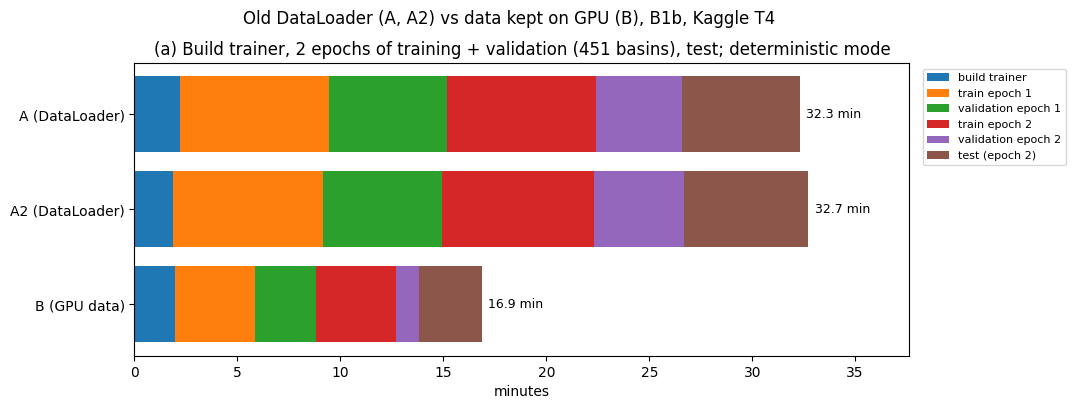

Hình: thời gian từng thành phần của 3 run B1b 2 epoch, chế độ tất định. Bộ nạp mới rút huấn luyện từ 7.34 xuống 3.86 phút/epoch, validation từ epoch 2 từ 4.26 xuống 1.12 phút; dựng trainer như nhau vì cùng đọc dữ liệu từ đĩa.
=> Đạt: bộ nạp mới cho kết quả trùng từng bit với bộ nạp cũ. Chạy Phần 8.


tệp,KB,sha256
Figures/G0_RunTime.png,66.50,d8eaf6cb1578...
G0_A.log,8.20,1311ed6477d9...
G0_A2.log,8.20,2fee1f616fa9...
G0_A2_steps.csv,191.30,52fc3d90cac8...
G0_A2_test.csv,18.30,e242311493ae...
G0_A2_validation_epoch1.csv,18.30,22151904d056...
G0_A2_validation_epoch2.csv,18.30,9109f98ffbf6...
G0_A_steps.csv,191.30,52fc3d90cac8...
G0_A_test.csv,18.30,e242311493ae...
G0_A_validation_epoch1.csv,18.30,22151904d056...


Thư mục khác còn trong /kaggle/working: ['__notebook__.ipynb']
=> Xong notebook.


In [1]:
# %% Phần 1 - Bật chế độ tất định, cài fork nhánh gpu-loader, kiểm mã đã cài, kiểm môi trường
# Đặt CUBLAS_WORKSPACE_CONFIG trước khi nạp torch: cuBLAS chỉ tất định khi có biến này lúc tạo handle (tài liệu PyTorch 2.11
# notes/randomness, torch.use_deterministic_algorithms). Rồi cài fork đúng commit f229e02 (nhánh gpu-loader = e794d7c
# + data_on_gpu + kiểm thử), tải 5 tệp liên quan của cùng commit (git fetch --depth 1) và so từng byte với bản đã cài.
# Bật use_deterministic_algorithms(True, warn_only=True): phép tính nào không có bản tất định chỉ báo cảnh báo (Phần 4-6
# ghi lại) thay vì dừng notebook; thư viện không tự đổi cờ cuDNN (basetrainer.py dòng 427-435 chỉ đặt hạt giống).
import importlib
import importlib.metadata as md
import json
import os
import platform
import shutil
import subprocess
import sys
from pathlib import Path

CUBLAS_CFG = ":4096:8"
TORCH_LOADED_BEFORE = "torch" in sys.modules   # đã nạp từ trước (cell khác) => biến môi trường có thể không tác dụng
os.environ["CUBLAS_WORKSPACE_CONFIG"] = CUBLAS_CFG

import pandas as pd
from IPython.display import HTML, display

NH_REPO = "https://github.com/Ticasslo/neuralhydrology.git"
NH_COMMIT = "f229e02bf98cbd979835a4b6cd503d0e3adb8bc3"   # nhánh gpu-loader
NH_BASE = "e794d7c"                                      # commit research mà nhánh gpu-loader tách ra
NH_FILES = ["neuralhydrology/datautils/gpu_loader.py", "neuralhydrology/training/basetrainer.py",
            "neuralhydrology/evaluation/tester.py", "neuralhydrology/datasetzoo/basedataset.py",
            "neuralhydrology/utils/config.py"]
CHECK_LIBS = ["numpy", "pandas", "xarray", "torch", "scipy", "numba", "ruamel.yaml", "matplotlib", "tensorboard", "tqdm"]
NH_MODULES = ["neuralhydrology.datautils.gpu_loader", "neuralhydrology.training.basetrainer",
              "neuralhydrology.evaluation.tester", "neuralhydrology.modelzoo.sequential_forecast_lstm"]
TORCH_A4 = "2.11.0+cu128"                # torch của A4 và notebook đo bộ nạp; khác thì chỉ cảnh báo

IS_KAGGLE = Path("/kaggle/working").exists()
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("g0_work")
OUT_DIR = WORK_DIR / "g0_output"         # bảng, môi trường, danh mục tệp (Phần 4-7)
SRC_DIR = WORK_DIR / "g0_nh_src"         # tạm, xóa sau khi so mã
WORK_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)


def installed_versions(libs):
    # Phiên bản đang cài trên đĩa (không phụ thuộc thứ đã nạp vào bộ nhớ).
    out = {}
    for lib in libs:
        try:
            out[lib] = md.version(lib)
        except md.PackageNotFoundError:
            out[lib] = None
    return out


def mem_gb(key):
    # Đọc /proc/meminfo (kB) => GB.
    for line in Path("/proc/meminfo").read_text().splitlines():
        if line.startswith(key + ":"):
            return int(line.split()[1]) / 1024 ** 2
    return None


def cpu_model():
    # Tên CPU từ /proc/cpuinfo (dòng "model name" đầu tiên).
    for line in Path("/proc/cpuinfo").read_text().splitlines():
        if line.startswith("model name"):
            return line.split(":", 1)[1].strip()
    return "không rõ"


def show(title, df):
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    display(df.style.hide(axis="index").format(precision=2))  # số thực in 2 chữ số thập phân


def run(cmd, cwd=None, stdout_only=False):
    # Chạy lệnh, trả (mã thoát, output); stdout_only cho git show (nội dung tệp, không lẫn cảnh báo ở stderr).
    p = subprocess.run(cmd, cwd=cwd, capture_output=True, text=True)
    return p.returncode, p.stdout if stdout_only else p.stdout + p.stderr


before = installed_versions(CHECK_LIBS)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"git+{NH_REPO}@{NH_COMMIT}"], check=True)
after = installed_versions(CHECK_LIBS)
importlib.invalidate_caches()  # để tiến trình đang chạy thấy gói vừa cài

# Xác nhận pip cài đúng commit (pip ghi nguồn cài vào direct_url.json)
direct = json.loads(md.distribution("neuralhydrology").read_text("direct_url.json") or "{}")
installed_commit = direct.get("vcs_info", {}).get("commit_id")
changed = [k for k in CHECK_LIBS if before[k] != after[k]]
show("Thư viện (sau khi cài fork)", pd.DataFrame({
    "Thư viện": ["neuralhydrology"] + CHECK_LIBS,
    "Phiên bản": [f"{md.version('neuralhydrology')} (commit {installed_commit[:7] if installed_commit else '?'})"]
                 + [after[k] or "THIẾU" for k in CHECK_LIBS],
    "pip đổi?": [""] + [f"từ {before[k]}" if k in changed else "" for k in CHECK_LIBS]}))

import torch  # nạp sau khi đặt biến môi trường và cài fork

CUDA_INIT_BEFORE = TORCH_LOADED_BEFORE and torch.cuda.is_initialized()
torch.use_deterministic_algorithms(True, warn_only=True)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

n_gpu = torch.cuda.device_count()
gpus = [f"{i}: {torch.cuda.get_device_name(i)} (cc {'.'.join(map(str, torch.cuda.get_device_capability(i)))}, "
        f"{torch.cuda.get_device_properties(i).total_memory / 1024 ** 3:.1f} GB)" for i in range(n_gpu)]
build_date = Path("/etc/build_date").read_text().strip() if Path("/etc/build_date").exists() else "không có"
ENV = {
    "Python": platform.python_version(),
    "torch / CUDA của torch": f"{torch.__version__} / {torch.version.cuda}",
    "cuDNN": torch.backends.cudnn.version(),
    "Số GPU": n_gpu,
    "GPU": "; ".join(gpus) or "không có GPU",
    "CPU": cpu_model(),
    "Số CPU (os.cpu_count / được dùng)": f"{os.cpu_count()} / {len(os.sched_getaffinity(0))}",
    "RAM tổng / còn trống (GB)": f"{mem_gb('MemTotal'):.1f} / {mem_gb('MemAvailable'):.1f}",
    "Đĩa trống ở WORK_DIR (GB)": f"{shutil.disk_usage(WORK_DIR).free / 1024 ** 3:.1f}",
    "Ngày dựng ảnh Kaggle": build_date,
    "CUBLAS_WORKSPACE_CONFIG": os.environ.get("CUBLAS_WORKSPACE_CONFIG"),
    "use_deterministic_algorithms / chỉ cảnh báo": f"{torch.are_deterministic_algorithms_enabled()} / "
                                                   f"{torch.is_deterministic_algorithms_warn_only_enabled()}",
    "cudnn.deterministic / cudnn.benchmark": f"{torch.backends.cudnn.deterministic} / {torch.backends.cudnn.benchmark}",
}
show("Môi trường", pd.DataFrame({"Mục": list(ENV), "Giá trị": [str(v) for v in ENV.values()]}))

# Thử nạp các module sẽ dùng: bộ nạp mới, vòng huấn luyện, validation/test, mô hình SeqLSTM
import_ok = {}
for mod in NH_MODULES:
    try:
        importlib.import_module(mod)
        import_ok[mod] = "ĐẠT"
    except Exception as e:  # in lỗi thật để biết thiếu gì
        import_ok[mod] = f"LỖI: {type(e).__name__}: {e}"

# Tải 5 tệp của đúng commit (chỉ commit đó, không cả lịch sử) rồi so với bản đã cài
shutil.rmtree(SRC_DIR, ignore_errors=True)
SRC_DIR.mkdir(parents=True)
git_log = []
for cmd in (["git", "init", "-q"], ["git", "remote", "add", "origin", NH_REPO],
            ["git", "fetch", "-q", "--depth", "1", "origin", NH_COMMIT]):
    code, out = run(cmd, cwd=SRC_DIR)
    git_log.append(out)
    if code != 0:
        break
nh_root = Path(importlib.import_module("neuralhydrology").__file__).parent.parent
same = {}
for f in NH_FILES:
    _, src = run(["git", "show", f"FETCH_HEAD:{f}"], cwd=SRC_DIR, stdout_only=True)
    same[f] = bool(src) and (nh_root / f).read_text() == src
shutil.rmtree(SRC_DIR, ignore_errors=True)
show(f"Mã đã cài so với commit {NH_COMMIT[:7]}", pd.DataFrame({
    "Tệp": [f.split("/", 1)[1] for f in NH_FILES], "Trùng từng byte": ["ĐẠT" if v else "KHÔNG" for v in same.values()]}))

from neuralhydrology.utils.config import Config

checks = {
    f"Cài đúng commit {NH_COMMIT[:7]} (nhánh gpu-loader)": installed_commit == NH_COMMIT,
    "pip không đổi thư viện có sẵn": not changed,
    "Có GPU T4": n_gpu >= 1 and "T4" in gpus[0],
    "Có tensorboard (training/logger.py nạp khi import)": after["tensorboard"] is not None,
    **{f"Nạp {m.split('.')[-1]}": v == "ĐẠT" for m, v in import_ok.items()},
    "5 tệp liên quan trùng commit": all(same.values()),
    "Config có khóa data_on_gpu": isinstance(getattr(Config, "data_on_gpu", None), property),
    f"CUBLAS_WORKSPACE_CONFIG = {CUBLAS_CFG} trước khi CUDA khởi động": (
        os.environ.get("CUBLAS_WORKSPACE_CONFIG") == CUBLAS_CFG and not CUDA_INIT_BEFORE),
    "Bật chế độ tất định (use_deterministic_algorithms, cudnn)": (
        torch.are_deterministic_algorithms_enabled() and torch.backends.cudnn.deterministic
        and not torch.backends.cudnn.benchmark),
}
show("Điều kiện", pd.DataFrame({"Điều kiện": list(checks), "Đạt": ["ĐẠT" if v else "KHÔNG" for v in checks.values()]}))
for mod, v in import_ok.items():
    if v != "ĐẠT":
        print(f"{mod}: {v}")
if not all(same.values()):
    print("\n".join(git_log))
if CUDA_INIT_BEFORE:
    print("CUDA đã khởi động trước Phần 1 => Restart kernel rồi chạy Phần 1 đầu tiên.")

if torch.__version__ != TORCH_A4:
    print(f"Cảnh báo: torch {torch.__version__} khác bản của A4 ({TORCH_A4}) - ảnh Kaggle đã đổi; ghi lại khi so sánh.")
if changed:
    print("Cảnh báo: pip đã đổi thư viện có sẵn - ghi lại khi so sánh.")
# Save & Run All không dừng ở dòng in => lỗi phải raise để không tốn giờ GPU cho các Phần sau
if not all(v for k, v in checks.items() if k != "pip không đổi thư viện có sẵn"):
    raise RuntimeError("Phần 1 CHƯA đạt (dòng KHÔNG ở bảng Điều kiện) - dừng notebook")
print("=> Đạt. Chạy Phần 2.")


# %% Phần 2 - Tìm dữ liệu, config tác giả, dựng thư mục dữ liệu có cột qmean_mmd, qmax_mmd
# Chép nguyên Phần 2-3 của notebook đo bộ nạp (02_0_DataLoader_Benchmark.py, Version 1 đạt), chỉ gộp thành một Phần.
# (1)-(3) Đọc config run SeqLSTM có Q nhúng đơn giản của tác giả (nền của A4, B0), kiểm đúng run, xếp khóa: giữ / đổi ở
# Phần 3 / bỏ. dynamic_inputs của tác giả phải = hindcast_inputs + forecast_inputs (basedataset.py dòng 350-353, 172-176);
# tên cột mới nằm ngoài _VALID_TARGETS của bộ nạp (lamah.py dòng 18, 119-131).
# (4)-(6) Bộ nạp chỉ đọc đầu vào từ tệp khí tượng, Q nằm ở D_gauges => thêm qmean_mmd, qmax_mmd (mm/ngày theo area_gov,
# đổi bằng chính hàm thư viện dùng cho nhãn) vào tệp khí tượng của 451 lưu vực; kiểm cột cũ giữ nguyên, qmax_mmd trùng
# nhãn qmax, cùng mặt nạ, không âm, qmax_mmd >= qmean_mmd.
import random
import time

import numpy as np
from neuralhydrology.datasetzoo.lamah import (_VALID_TARGETS, _normalize_discharge, load_lamah_attributes,
                                              load_lamah_discharge, load_lamah_forcing)
from ruamel.yaml import YAML

SEARCH_ROOT = Path(os.environ.get("LAMAH_ROOT", "/kaggle/input" if IS_KAGGLE else "."))
AUTHOR_RUN_REL = ("Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/"
                  "Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding")
N_BASINS = 451
Q_OLD = "qmean"                          # cột Q quá khứ của tác giả (m³/s)
Q_NEW = ["qmean_mmd", "qmax_mmd"]        # cột Q quá khứ của B1b (mm/ngày theo area_gov), dựng ở (4)
# Giá trị phải có trong config tác giả (báo cáo A4) - lệch là đọc nhầm run
EXPECTED = {"model": "sequential_forecast_lstm", "seed": 111, "hidden_size": 128, "batch_size": 256, "epochs": 30,
            "learning_rate": 0.001, "output_dropout": 0.3, "seq_length": 365, "forecast_seq_length": 1,
            "early_stopping_patience": 5, "early_stopping_min_delta": 0.005, "early_stopping_metric": "NSE",
            "loss": "NSE", "clip_gradient_norm": 1, "target_variables": ["qmax"]}
# Khóa sẽ đổi ở Phần 3 (đường dẫn, thiết bị, số tiến trình đọc, thanh tiến độ, tên run, biến quá khứ, dừng sớm, số epoch,
# bộ nạp) và khóa bỏ
KEYS_CHANGE = ["data_dir", "run_dir", "train_basin_file", "validation_basin_file", "test_basin_file", "device",
               "num_workers", "verbose", "experiment_name", "hindcast_inputs", "dynamic_inputs", "early_stopping_patience",
               "epochs", "data_on_gpu"]
KEYS_DROP = ["commit_hash", "package_version", "number_of_basins", "train_dir", "img_log_dir"]


def find_dir(root, name):
    # Thư mục duy nhất tên `name` dưới `root`; báo lỗi rõ nếu không có hoặc có nhiều.
    hits = sorted(p for p in root.rglob(name) if p.is_dir())
    if len(hits) != 1:
        raise FileNotFoundError(f"Cần đúng 1 thư mục '{name}' dưới {root}, thấy {len(hits)}: {hits} - kiểm Input lamah-ce-ext")
    return hits[0]


def brief(value, width=90):
    # Rút gọn giá trị config để bảng dễ đọc (danh sách dài => số phần tử + vài phần tử đầu).
    if isinstance(value, list) and len(value) > 4:
        text = f"[{len(value)}] " + ", ".join(map(str, value[:3])) + ", ..."
    else:
        text = str(value)
    return text if len(text) <= width else text[:width - 3] + "..."


# (1) Đường dẫn, danh sách lưu vực, config của run tác giả
LAMAH_DIR = find_dir(SEARCH_ROOT, "LamaH_extended")
EXP_DIR = find_dir(SEARCH_ROOT, "Experiments")
BASIN_FILE = EXP_DIR / "basins_filtered.txt"
basins = BASIN_FILE.read_text().split()
AUTHOR_CFG_FILE = EXP_DIR / AUTHOR_RUN_REL / "config.yml"
show("Đường dẫn và tệp", pd.DataFrame(
    [("Dữ liệu", str(LAMAH_DIR), ""), ("Kết quả tác giả", str(EXP_DIR), ""),
     ("Danh sách lưu vực", str(BASIN_FILE), f"{len(basins)} lưu vực, {len(set(basins))} mã khác nhau"),
     ("Config run tác giả", str(AUTHOR_CFG_FILE.relative_to(EXP_DIR)), "có" if AUTHOR_CFG_FILE.exists() else "THIẾU")],
    columns=["mục", "đường dẫn", "ghi chú"]))
if len(basins) != N_BASINS or len(set(basins)) != N_BASINS or not AUTHOR_CFG_FILE.exists():
    raise RuntimeError("Thiếu config run tác giả hoặc danh sách lưu vực không đủ 451 mã khác nhau")

# (2) Config tác giả: kiểm đúng run, vị trí qmean, tên cột mới
AUTHOR_CFG = YAML(typ="safe").load(AUTHOR_CFG_FILE.read_text(encoding="utf-8"))
exp_rows = [{"khóa": k, "mong đợi": brief(v), "trong config": brief(AUTHOR_CFG.get(k)),
             "khớp": "ĐẠT" if AUTHOR_CFG.get(k) == v else "KHÔNG"} for k, v in EXPECTED.items()]
groups = {"hindcast_inputs": AUTHOR_CFG["hindcast_inputs"], "forecast_inputs": AUTHOR_CFG["forecast_inputs"],
          "static_attributes": AUTHOR_CFG["static_attributes"]}
hind = groups["hindcast_inputs"]
dyn = AUTHOR_CFG["dynamic_inputs"]
dyn_ok = dyn == hind + groups["forecast_inputs"]
all_inputs = dyn + hind + groups["forecast_inputs"] + groups["static_attributes"]
new_in_cfg = [c for c in Q_NEW if c in all_inputs]
new_in_targets = [c for c in Q_NEW if c.lower() in _VALID_TARGETS]
exp_rows += [{"khóa": "số biến quá khứ / ngày t / thuộc tính", "mong đợi": "32 / 5 / 33",
              "trong config": " / ".join(str(len(v)) for v in groups.values()),
              "khớp": "ĐẠT" if [len(v) for v in groups.values()] == [32, 5, 33] else "KHÔNG"},
             {"khóa": f"{Q_OLD} ở pha quá khứ, đúng 1 lần", "mong đợi": "1 lần", "trong config": f"{hind.count(Q_OLD)} lần",
              "khớp": "ĐẠT" if hind.count(Q_OLD) == 1 else "KHÔNG"},
             {"khóa": "dynamic_inputs = hindcast_inputs + forecast_inputs (đúng thứ tự)", "mong đợi": "trùng",
              "trong config": f"{len(dyn)} biến, " + ("trùng" if dyn_ok else "KHÁC"), "khớp": "ĐẠT" if dyn_ok else "KHÔNG"},
             {"khóa": f"{Q_OLD} không ở pha ngày t", "mong đợi": "không",
              "trong config": "có" if Q_OLD in groups["forecast_inputs"] else "không",
              "khớp": "ĐẠT" if Q_OLD not in groups["forecast_inputs"] else "KHÔNG"},
             {"khóa": "tên cột mới chưa có trong config", "mong đợi": "chưa có",
              "trong config": ", ".join(new_in_cfg) or "chưa có", "khớp": "ĐẠT" if not new_in_cfg else "KHÔNG"},
             {"khóa": "tên cột mới ngoài _VALID_TARGETS của bộ nạp", "mong đợi": f"ngoài {_VALID_TARGETS}",
              "trong config": ", ".join(new_in_targets) or "ngoài", "khớp": "ĐẠT" if not new_in_targets else "KHÔNG"}]
show("Kiểm đúng run SeqLSTM có Q nhúng đơn giản", pd.DataFrame(exp_rows))
print(f"Biến quá khứ của tác giả ({len(hind)}), {Q_OLD} ở vị trí {hind.index(Q_OLD) + 1 if Q_OLD in hind else '-'}:")
print(", ".join(hind))

# (3) Mọi khóa config: giữ / đổi ở Phần 3 / bỏ
key_rows = []
for k in sorted(set(AUTHOR_CFG) | set(KEYS_CHANGE)):
    action = "đổi ở Phần 3" if k in KEYS_CHANGE else ("bỏ (thư viện tự ghi)" if k in KEYS_DROP else "giữ")
    key_rows.append({"khóa": k, "giá trị tác giả": brief(AUTHOR_CFG.get(k, "(không có, mặc định)")), "xử lý": action})
key_df = pd.DataFrame(key_rows).sort_values(["xử lý", "khóa"], key=lambda s: s.map(
    {"đổi ở Phần 3": 0, "bỏ (thư viện tự ghi)": 1, "giữ": 2}) if s.name == "xử lý" else s)
show(f"Khóa config ({len(AUTHOR_CFG)} khóa của tác giả): {sum(key_df['xử lý'] == 'giữ')} giữ, "
     f"{sum(key_df['xử lý'] == 'đổi ở Phần 3')} đổi, {sum(key_df['xử lý'].str.startswith('bỏ'))} bỏ", key_df)

if not all(r["khớp"] == "ĐẠT" for r in exp_rows):
    raise RuntimeError("Phần 2 CHƯA đạt (kiểm config tác giả, dòng KHÔNG ở trên) - dừng notebook")

Q_DIR = WORK_DIR / "LamaH_q_mmd_input"
SUB_A = "A_basins_total_upstrm"
TS_DAILY = Path("2_timeseries") / "daily"
DATE_COLS = ["YYYY", "MM", "DD"]
Q_SRC = {"qmean_mmd": "qmean", "qmax_mmd": "qmax"}  # cột mới => cột của D_gauges
assert list(Q_SRC) == Q_NEW
N_CHECK = 3
LABEL_TOL = 1e-12  # lệch tương đối tối đa cho phép giữa qmax_mmd và nhãn (0 nếu đọc lại đúng từng bit)
random.seed(0)


def read_text_csv(path, usecols=None):
    # Đọc CSV ';' dạng chữ (không đổi sang số), ô trống giữ là chuỗi rỗng; thêm khóa ngày dạng số để ghép.
    df = pd.read_csv(path, sep=";", dtype=str, keep_default_na=False, usecols=usecols)
    df["_key"] = pd.to_datetime(df[DATE_COLS].astype(int).rename(columns={"YYYY": "year", "MM": "month", "DD": "day"}))
    return df


def q_mmd(data_dir, basin, src):
    # Q (m³/s) của D_gauges => mm/ngày theo area_gov, đúng các hàm bộ nạp gọi cho nhãn.
    ser = load_lamah_discharge(data_dir, basin, temporal_resolution="1D", normalize_discharge=False, target_name=src)[src]
    return _normalize_discharge(ser=ser, area=AREA.loc[basin], temporal_resolution="1D")


def fmt(ser):
    # float64 => chữ 17 chữ số có nghĩa, NaN => ô trống
    return ser.map(lambda v: "" if pd.isna(v) else format(v, ".17g"))


def build_basin_file(basin):
    # Ghép 2 cột Q mm/ngày vào tệp khí tượng theo ngày; ghi qua tệp tạm rồi đổi tên để không để lại tệp dở.
    forcing = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv")
    for new, src in Q_SRC.items():
        forcing[new] = fmt(forcing["_key"].map(q_mmd(LAMAH_DIR, basin, src)))
    dst = Q_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv"
    tmp = dst.with_suffix(".tmp")
    forcing.drop(columns="_key").to_csv(tmp, sep=";", index=False)
    tmp.rename(dst)


def has_new_cols(path):
    return path.exists() and all(c in path.open().readline().strip().split(";") for c in Q_NEW)


# (4) Dựng thư mục
t0 = time.time()
AREA = load_lamah_attributes(LAMAH_DIR, sub_dataset="lamah_a")["area_gov"]
(Q_DIR / SUB_A / TS_DAILY).mkdir(parents=True, exist_ok=True)
for link, target in [(Q_DIR / SUB_A / "1_attributes", LAMAH_DIR / SUB_A / "1_attributes"),
                     (Q_DIR / "D_gauges", LAMAH_DIR / "D_gauges")]:
    if not (link.exists() or link.is_symlink()):
        link.symlink_to(target, target_is_directory=True)
todo = [b for b in basins if not has_new_cols(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")]
for b in todo:
    build_basin_file(b)
files = [Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv" for b in basins]
n_ok = sum(has_new_cols(f) for f in files)
show("Thư mục Q đã dựng", pd.DataFrame([
    ("Thư mục", str(Q_DIR)),
    ("Tệp khí tượng có qmean_mmd, qmax_mmd", f"{n_ok} / {len(basins)} (dựng mới {len(todo)}, có sẵn {len(basins) - len(todo)})"),
    ("Dung lượng", f"{sum(f.stat().st_size for f in files if f.exists()) / 1e9:.2f} GB"),
    ("Liên kết", "A_basins_total_upstrm/1_attributes, D_gauges => bản gốc"),
    ("Thời gian dựng", f"{time.time() - t0:.0f} giây"),
], columns=["mục", "giá trị"]))

# (5) 3 lưu vực ngẫu nhiên: cột cũ giữ nguyên từng ký tự, chỉ thêm đúng 2 cột
rows = []
for b in random.sample(basins, N_CHECK):
    src = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    new = read_text_csv(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    rows.append({"lưu vực": b, "số cột cũ / mới": f"{src.shape[1] - 1} / {new.shape[1] - 1}",
                 "cột thêm": ", ".join(c for c in new.columns if c not in src.columns),
                 "cột cũ giữ nguyên": "ĐẠT" if new.drop(columns=Q_NEW).equals(src) else "KHÔNG"})
show(f"Kiểm {N_CHECK} lưu vực ngẫu nhiên (số cột không tính cột khóa ngày)", pd.DataFrame(rows))

# (6) Cả 451 lưu vực, đọc lại bằng đường của bộ nạp. Nhãn: load_lamah_discharge + _normalize_discharge trên Q_DIR,
#     căn theo ngày của tệp khí tượng như _load_basin_data (lamah.py dòng 108-131).
cfg_author = Config(AUTHOR_CFG_FILE)
win_start = cfg_author.train_start_date - pd.Timedelta(days=cfg_author.seq_length - 1)  # khởi động của kỳ train
win_end = cfg_author.test_end_date
t1 = time.time()
area_q = load_lamah_attributes(Q_DIR, sub_dataset="lamah_a")["area_gov"]
assert area_q.loc[basins].equals(AREA.loc[basins]), "area_gov đọc từ thư mục Q khác bản gốc"
n_days = n_label_diff = n_mask_diff = n_neg = n_order = 0
max_rel = 0.0
bad_label, bad_mask = [], []
for b in basins:
    df = load_lamah_forcing(Q_DIR, b, sub_dataset="lamah_a")
    label = q_mmd(Q_DIR, b, "qmax").reindex(df.index)
    w = df.loc[win_start:win_end]
    qm, qx, lab = w["qmean_mmd"].to_numpy(), w["qmax_mmd"].to_numpy(), label.loc[win_start:win_end].to_numpy()
    same_nan = np.isnan(qx) == np.isnan(lab)
    both = ~np.isnan(qx) & ~np.isnan(lab)
    rel = np.abs(qx[both] - lab[both]) / np.maximum(np.abs(lab[both]), 1e-300)
    n_days += len(w)
    n_label_diff += int((~same_nan).sum() + (rel > 0).sum())
    max_rel = max(max_rel, float(rel.max()) if rel.size else 0.0)
    mask_diff = int((np.isnan(qm) != np.isnan(qx)).sum())
    n_mask_diff += mask_diff
    n_neg += int((qm < 0).sum() + (qx < 0).sum())
    n_order += int((qx < qm).sum())
    if (~same_nan).any():
        bad_label.append(b)
    if mask_diff:
        bad_mask.append(b)
show(f"Kiểm cả {len(basins)} lưu vực, {win_start.date()} - {win_end.date()} ({time.time() - t1:.0f} giây)", pd.DataFrame([
    {"kiểm": "ngày-lưu vực đã kiểm", "kết quả": f"{n_days:,}", "đạt": ""},
    {"kiểm": "ô qmax_mmd lệch nhãn qmax ở mức làm tròn số (lệch > 0, xem dòng dưới)", "kết quả": f"{n_label_diff:,}",
     "đạt": ""},
    {"kiểm": "lệch tương đối lớn nhất qmax_mmd so với nhãn", "kết quả": f"{max_rel:.3g}",
     "đạt": "ĐẠT" if max_rel <= LABEL_TOL else "KHÔNG"},
    {"kiểm": "ô trống qmax_mmd khác ô trống nhãn", "kết quả": f"{len(bad_label)} lưu vực", "đạt": "ĐẠT" if not bad_label else "KHÔNG"},
    {"kiểm": "mặt nạ qmean_mmd khác qmax_mmd", "kết quả": f"{n_mask_diff:,} ngày-lưu vực, {len(bad_mask)} lưu vực",
     "đạt": "ĐẠT" if n_mask_diff == 0 else "KHÔNG"},
    {"kiểm": "giá trị âm", "kết quả": f"{n_neg:,}", "đạt": "ĐẠT" if n_neg == 0 else "KHÔNG"},
    {"kiểm": "qmax_mmd < qmean_mmd", "kết quả": f"{n_order:,}", "đạt": "ĐẠT" if n_order == 0 else "KHÔNG"}]))
for name, ids in [("ô trống khác nhãn", bad_label), ("mặt nạ qmean_mmd khác qmax_mmd", bad_mask)]:
    if ids:
        print(f"Lưu vực {name}:", ", ".join(ids[:20]), "..." if len(ids) > 20 else "")

ok = n_ok == len(basins) and all(r["cột cũ giữ nguyên"] == "ĐẠT" for r in rows) and max_rel <= LABEL_TOL \
    and not bad_label and n_mask_diff == 0 and n_neg == 0 and n_order == 0
if not ok:
    raise RuntimeError("Phần 2 CHƯA đạt (thư mục Q, dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 3.")


# %% Phần 3 - Config B1b 2 epoch cho 3 run: A, A2 (bộ nạp cũ), B (bộ nạp mới)
# Dựng như Phần 4 của notebook đo (đọc config tác giả round-trip giữ thứ tự, đổi đúng KEYS_CHANGE, bỏ KEYS_DROP):
# qmean => qmean_mmd tại cùng vị trí, thêm qmax_mmd ngay sau; early_stopping_patience 30 (giao thức từ B0, không dừng sớm
# nhưng vẫn lưu best_model.pt); num_workers 2 như A4; epochs 2 (đủ để thấy trọng số, loss, validation qua hai epoch và
# lượt validation thứ hai dùng dataset đã giữ). Ba config chỉ khác experiment_name và data_on_gpu (False, False, True).
# Kiểm: config A chỉ khác tác giả ở khóa đã liệt kê; ba config khác nhau đúng 2 khóa đó; Config của thư viện đọc được
# data_on_gpu đúng giá trị; 33 / 5 / 38 biến quá khứ / ngày t / động. Chung run_dir: thư viện tự tạo thư mục con
# <experiment_name>_<ngày giờ> cho mỗi run (basetrainer.py dòng 470-484).
CFG_DIR = WORK_DIR / "g0_configs"
RUNS_DIR = WORK_DIR / "g0_runs"
RUNS = {"A": False, "A2": False, "B": True}   # tên run => data_on_gpu
N_EPOCHS = 2
N_WORKERS_NOW = 2                             # như A4; bộ nạp mới không dùng tiến trình đọc phụ


def swap_q(inputs):
    # qmean => qmean_mmd tại cùng vị trí, chèn qmax_mmd ngay sau.
    i = inputs.index(Q_OLD)
    return inputs[:i] + Q_NEW + inputs[i + 1:]


def cfg_path(name):
    return CFG_DIR / f"G0_B1b_{name}.yml"


yaml_rt = YAML()
yaml_rt.width = 4096
CFG_DIR.mkdir(parents=True, exist_ok=True)
for name, on_gpu in RUNS.items():
    cfg_rt = yaml_rt.load(AUTHOR_CFG_FILE.read_text(encoding="utf-8"))
    new_vals = {"data_dir": str(Q_DIR), "run_dir": str(RUNS_DIR), "train_basin_file": str(BASIN_FILE),
                "validation_basin_file": str(BASIN_FILE), "test_basin_file": str(BASIN_FILE), "device": "cuda:0",
                "num_workers": N_WORKERS_NOW, "verbose": 0, "experiment_name": cfg_path(name).stem,
                "hindcast_inputs": swap_q(list(cfg_rt["hindcast_inputs"])),
                "dynamic_inputs": swap_q(list(cfg_rt["dynamic_inputs"])),
                "early_stopping_patience": 30, "epochs": N_EPOCHS, "data_on_gpu": on_gpu}
    assert set(new_vals) == set(KEYS_CHANGE), "new_vals phải đúng các khóa KEYS_CHANGE của Phần 2"
    for k in KEYS_DROP:
        cfg_rt.pop(k, None)
    cfg_rt.update(new_vals)
    with open(cfg_path(name), "w", encoding="utf-8") as f:
        yaml_rt.dump(cfg_rt, f)

loaded = {name: YAML(typ="safe").load(cfg_path(name).read_text(encoding="utf-8")) for name in RUNS}
new = loaded["A"]
diff_rows = [{"khóa": k, "tác giả": brief(AUTHOR_CFG.get(k, "(không có)"), 60), "run A": brief(new.get(k, "(bỏ)"), 60),
              "được phép": "ĐẠT" if k in KEYS_CHANGE + KEYS_DROP else "KHÔNG"}
             for k in sorted(set(AUTHOR_CFG) | set(new)) if AUTHOR_CFG.get(k, "(không có)") != new.get(k, "(bỏ)")]
show("Run A: khóa khác config tác giả", pd.DataFrame(diff_rows))


def keys_differ(a, b):
    return sorted(k for k in set(a) | set(b) if a.get(k) != b.get(k))


pair_rows = [{"cặp": f"{x} - {y}", "khóa khác nhau": ", ".join(keys_differ(loaded[x], loaded[y]))}
             for x, y in [("A", "A2"), ("A", "B"), ("A2", "B")]]
show("Ba config chỉ khác nhau ở", pd.DataFrame(pair_rows))

cfgs = {name: Config(cfg_path(name)) for name in RUNS}
show("Config thư viện đọc được", pd.DataFrame([
    {"run": name, "tệp": cfg_path(name).name, "data_on_gpu": c.data_on_gpu, "epochs": c.epochs,
     "early_stopping_patience": c.early_stopping_patience, "num_workers": c.num_workers,
     "biến quá khứ / ngày t / động": f"{len(c.hindcast_inputs)} / {len(c.forecast_inputs)} / {len(c.dynamic_inputs)}"}
    for name, c in cfgs.items()]))

checks3 = {
    "run A chỉ đổi khóa đã liệt kê": all(r["được phép"] == "ĐẠT" for r in diff_rows),
    "A, A2 chỉ khác experiment_name": keys_differ(loaded["A"], loaded["A2"]) == ["experiment_name"],
    "A, B chỉ khác data_on_gpu, experiment_name": keys_differ(loaded["A"], loaded["B"]) == ["data_on_gpu", "experiment_name"],
    "data_on_gpu: A False, A2 False, B True": [c.data_on_gpu for c in cfgs.values()] == list(RUNS.values()),
    f"epochs {N_EPOCHS}, early_stopping_patience 30": all(c.epochs == N_EPOCHS and c.early_stopping_patience == 30
                                                          for c in cfgs.values()),
    "33 / 5 / 38 biến, ..., qmean_mmd, qmax_mmd cuối pha quá khứ": all(
        [len(c.hindcast_inputs), len(c.forecast_inputs), len(c.dynamic_inputs)] == [33, 5, 38]
        and c.hindcast_inputs[-2:] == Q_NEW for c in cfgs.values()),
}
show("Điều kiện", pd.DataFrame({"Điều kiện": list(checks3), "Đạt": ["ĐẠT" if v else "KHÔNG" for v in checks3.values()]}))
if not all(checks3.values()):
    raise RuntimeError("Phần 3 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 4.")


# %% Phần 4 - Run A: bộ nạp cũ, huấn luyện 2 epoch + validation, chấm test
# Hàm run_one dùng cho cả 3 run (Phần 4-6). Huấn luyện đúng như start_training (training/train.py dòng 15-20):
# BaseTrainer(cfg) => initialize_training() => train_and_validate(); gọi từng bước thay cho start_training để bọc đồng hồ
# quanh _train_epoch và validator.evaluate (đồng bộ GPU trước khi dừng đồng hồ) và ghi loss từng bước ở độ chính xác đầy
# đủ: _train_epoch gọi experiment_logger.log_step(**{k: v.item()}) mỗi bước (basetrainer.py dòng 425; khóa total_loss,
# loss.py dòng 133); validation cũng gọi log_step nhưng khi logger ở chế độ valid (_train False, logger.py dòng 65-73)
# => chỉ lấy bước có _train True. Rồi chấm test bằng start_evaluation(epoch=2) như lệnh nh-run evaluate
# (evaluation/evaluate.py dòng 7-23).
# Log thư viện ghi vào tệp riêng mỗi run, không in ra màn hình (setup_logging dùng logging.basicConfig, hàm này không làm
# gì khi root logger đã có handler - logging_utils.py dòng 10-28). Ghi lại cảnh báo của PyTorch về phép tính không có bản
# tất định (warn_only ở Phần 1). Mọi run bắt đầu từ cùng hạt giống 111 (BaseTrainer.__init__ gọi _set_random_seeds).
# Trong lúc chạy in một dòng tiến độ sau mỗi lần huấn luyện, validation, chấm test (log thư viện chỉ ghi vào tệp).
import gc
import logging
import warnings

from neuralhydrology.evaluation.evaluate import start_evaluation
from neuralhydrology.training.basetrainer import BaseTrainer

DEVICE = torch.device("cuda:0")
RESULTS = {}                             # tên run => kết quả, dùng ở Phần 7


def read_metrics(path):
    # Bảng chỉ số từng lưu vực của thư viện (basin + các cột chỉ số), sắp theo mã lưu vực.
    return pd.read_csv(path, dtype={"basin": str}).set_index("basin").sort_index()


def run_one(name):
    # Một run đủ: huấn luyện N_EPOCHS epoch + validation mỗi epoch, chấm test epoch cuối; trả dict kết quả.
    cfg = Config(cfg_path(name))
    logging.basicConfig(handlers=[logging.FileHandler(OUT_DIR / f"G0_{name}.log")], level=logging.INFO,
                        format="%(asctime)s: %(message)s", force=True)
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats(DEVICE)
    mem0 = torch.cuda.memory_allocated(DEVICE)
    clock = {}
    steps = []                           # (epoch, loss) của mọi bước huấn luyện, theo thứ tự
    epoch_now = [0]

    def timed(key, fn):
        # Bọc một phương thức: ghi thời gian (giây) vào clock[(key, epoch)], in một dòng tiến độ.
        def wrapper(*args, **kwargs):
            torch.cuda.synchronize(DEVICE)
            t0 = time.perf_counter()
            out = fn(*args, **kwargs)
            torch.cuda.synchronize(DEVICE)
            e = epoch_now[0]
            clock[(key, e)] = time.perf_counter() - t0
            if key == "train":
                loss_e = [l for ep, l in steps if ep == e]
                note = f"loss trung bình {np.mean(loss_e):.6f}"
            else:
                # evaluate trả {lưu vực: {tần suất: {chỉ số: giá trị}}} (như Phần 7 của notebook đo)
                nse = [next(iter(v.values())).get("NSE", np.nan) for v in out.values()]
                note = f"NSE trung vị {np.nanmedian(nse):.4f}"
            print(f"  [{name}] epoch {e} {key}: {clock[(key, e)] / 60:.2f} phút, {note}", flush=True)
            return out
        return wrapper

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        t0 = time.perf_counter()
        trainer = BaseTrainer(cfg=cfg)
        trainer.initialize_training()
        torch.cuda.synchronize(DEVICE)
        t_init = time.perf_counter() - t0
        mem_init = torch.cuda.memory_allocated(DEVICE) - mem0
        loader_type = type(trainer.loader).__name__
        n_batches = len(trainer.loader)
        print(f"  [{name}] dựng trainer {t_init:.0f} giây, bộ nạp {loader_type}, {n_batches:,} lô/epoch", flush=True)

        train_epoch, log_step = trainer._train_epoch, trainer.experiment_logger.log_step

        def train_epoch_spy(epoch):
            epoch_now[0] = epoch
            return train_epoch(epoch=epoch)

        def log_step_spy(**kwargs):
            if trainer.experiment_logger._train:
                steps.append((epoch_now[0], kwargs["total_loss"]))
            return log_step(**kwargs)

        trainer._train_epoch = timed("train", train_epoch_spy)
        trainer.experiment_logger.log_step = log_step_spy
        trainer.validator.evaluate = timed("validation", trainer.validator.evaluate)
        trainer.train_and_validate()
        run_dir = cfg.run_dir
        peak_train = torch.cuda.max_memory_allocated(DEVICE) - mem0
        del trainer
        gc.collect()
        torch.cuda.empty_cache()

        t0 = time.perf_counter()
        start_evaluation(cfg=cfg, run_dir=run_dir, epoch=N_EPOCHS, period="test")
        torch.cuda.synchronize(DEVICE)
        t_test = time.perf_counter() - t0
        print(f"  [{name}] chấm test epoch {N_EPOCHS}: {t_test / 60:.2f} phút", flush=True)
    for h in logging.getLogger().handlers:
        h.flush()

    det_warn = sorted({str(w.message).split("\n")[0] for w in caught if "determinis" in str(w.message)})
    steps = pd.DataFrame(steps, columns=["epoch", "loss"])
    steps.to_csv(OUT_DIR / f"G0_{name}_steps.csv", index=False)
    val = {e: read_metrics(run_dir / "validation" / f"model_epoch{e:03d}" / "validation_metrics.csv")
           for e in range(1, N_EPOCHS + 1)}
    test = read_metrics(run_dir / "test" / f"model_epoch{N_EPOCHS:03d}" / "test_metrics.csv")
    for e, df in val.items():
        df.to_csv(OUT_DIR / f"G0_{name}_validation_epoch{e}.csv")
    test.to_csv(OUT_DIR / f"G0_{name}_test.csv")
    weights = {e: torch.load(run_dir / f"model_epoch{e:03d}.pt", map_location="cpu", weights_only=True)
               for e in range(1, N_EPOCHS + 1)}
    return {"cfg": cfg, "run_dir": run_dir, "loader": loader_type, "n_batches": n_batches, "t_init": t_init,
            "clock": clock, "t_test": t_test, "steps": steps, "val": val, "test": test, "weights": weights,
            "mem_init_mb": mem_init / 2 ** 20, "peak_train_mb": peak_train / 2 ** 20, "det_warn": det_warn}


def show_run(name):
    # Bảng tóm tắt một run và kiểm run chạy đủ.
    r = RESULTS[name]
    rows = [("Bộ nạp huấn luyện", r["loader"]), ("Lô mỗi epoch", f"{r['n_batches']:,}"),
            ("Dựng trainer (initialize_training)", f"{r['t_init']:.0f} giây")]
    for e in range(1, N_EPOCHS + 1):
        loss_e = r["steps"].loc[r["steps"]["epoch"] == e, "loss"]
        rows += [(f"Epoch {e}: huấn luyện", f"{r['clock'][('train', e)] / 60:.2f} phút"),
                 (f"Epoch {e}: validation {N_BASINS} lưu vực", f"{r['clock'][('validation', e)] / 60:.2f} phút"),
                 (f"Epoch {e}: loss trung bình / NSE trung vị validation",
                  f"{loss_e.mean():.6f} / {r['val'][e]['NSE'].median():.4f}")]
    rows += [(f"Chấm test epoch {N_EPOCHS} (gồm dựng dataset test)", f"{r['t_test'] / 60:.2f} phút"),
             ("NSE trung vị test", f"{r['test']['NSE'].median():.4f}"),
             ("Bộ nhớ GPU dùng thêm sau khi dựng trainer (mô hình + dữ liệu để sẵn trên GPU) / đỉnh khi huấn luyện",
              f"{r['mem_init_mb']:.1f} / {r['peak_train_mb']:.0f} MB"),
             ("Cảnh báo phép tính không tất định", "; ".join(r["det_warn"]) or "không có")]
    show(f"Run {name} (data_on_gpu {r['cfg'].data_on_gpu})", pd.DataFrame(rows, columns=["mục", "giá trị"]))
    checks = {
        f"đủ {N_EPOCHS} epoch, mỗi epoch {r['n_batches']:,} bước":
            r["steps"].groupby("epoch").size().to_dict() == {e: r["n_batches"] for e in range(1, N_EPOCHS + 1)},
        "có trọng số mọi epoch": len(r["weights"]) == N_EPOCHS,
        f"validation, test đủ {N_BASINS} lưu vực": all(len(v) == N_BASINS for v in r["val"].values())
                                                    and len(r["test"]) == N_BASINS,
        "bộ nạp đúng data_on_gpu": r["loader"] == ("GpuBatchLoader" if r["cfg"].data_on_gpu else "DataLoader"),
    }
    show("Điều kiện", pd.DataFrame({"Điều kiện": list(checks), "Đạt": ["ĐẠT" if v else "KHÔNG" for v in checks.values()]}))
    if not all(checks.values()):
        raise RuntimeError(f"Run {name} CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")


shutil.rmtree(RUNS_DIR, ignore_errors=True)
RESULTS["A"] = run_one("A")
show_run("A")
print("=> Xong run A. Chạy Phần 5.")


# %% Phần 5 - Run A2: bộ nạp cũ lần hai (đo lệch tự nhiên giữa hai lần chạy giống hệt nhau)
# Cùng config với A (chỉ khác experiment_name), cùng hạt giống 111, cùng chế độ tất định. A2 trùng A từng bit => GPU chạy
# tất định, B phải trùng A từng bit; A2 lệch A => mức lệch A-A2 là trần cho lệch A-B (luật ghi ở đầu tệp, so ở Phần 7).
RESULTS["A2"] = run_one("A2")
show_run("A2")
print("=> Xong run A2. Chạy Phần 6.")


# %% Phần 6 - Run B: bộ nạp mới (data_on_gpu True)
# Cùng config với A (chỉ khác experiment_name, data_on_gpu), cùng hạt giống, cùng chế độ tất định. Trainer dùng GpuBatchLoader
# (basetrainer.py _get_data_loader), validation và chấm test dùng GpuBatchLoader từng lưu vực (tester.py _get_loader);
# num_workers không dùng. Dòng "bộ nhớ GPU dùng thêm sau khi dựng trainer" gồm dữ liệu train để sẵn trên GPU.
RESULTS["B"] = run_one("B")
show_run("B")
print("=> Xong run B. Chạy Phần 7.")


# %% Phần 7 - So 3 run: trọng số, loss từng bước, chỉ số từng lưu vực; thời gian từng epoch
# So từng cặp A-A2, A-B, A2-B trên: trọng số epoch 1, 2 (mọi tensor của state_dict), loss của 8.550 bước huấn luyện,
# NSE/KGE validation epoch 1, 2 và test epoch 2 của 451 lưu vực (NaN coi là bằng NaN). Mỗi mục ghi số phần tử khác nhau
# và lệch tuyệt đối lớn nhất. Luật ghi ở đầu tệp: A trùng A2 ở mọi mục => B phải trùng A ở mọi mục; nếu không => lệch
# lớn nhất A-B ở mỗi mục không vượt lệch A-A2 cùng mục.
# Thời gian: bảng từng thành phần cho 3 run và một hình (chữ tiếng Anh, chú thích tiếng Việt). Cả 3 run chạy chế độ tất
# định nên thời gian tuyệt đối chậm hơn chạy thường (A4 và notebook đo: 5,6-5,9 phút huấn luyện/epoch); so A với B là so
# cùng điều kiện.
import matplotlib.pyplot as plt

FIG_DIR = OUT_DIR / "Figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
PAIRS = [("A", "A2"), ("A", "B"), ("A2", "B")]


def caption(text):
    # Chú thích tiếng Việt in ngay dưới hình (chữ trong hình tiếng Anh).
    print(f"Hình: {text}")


def diff_arrays(x, y):
    # (số phần tử khác nhau, lệch tuyệt đối lớn nhất); NaN ở cùng chỗ coi là bằng nhau.
    x, y = np.asarray(x, dtype=np.float64), np.asarray(y, dtype=np.float64)
    if x.shape != y.shape:
        return np.inf, np.inf
    both_nan = np.isnan(x) & np.isnan(y)
    d = np.where(both_nan, 0.0, np.abs(x - y))
    d = np.where(np.isnan(d), np.inf, d)                 # NaN ở một bên => khác
    return int((d > 0).sum()), float(d.max()) if d.size else 0.0


def compare(r1, r2):
    # Mỗi mục so sánh => (số phần tử khác, lệch lớn nhất, tổng số phần tử).
    out = {}
    for e in range(1, N_EPOCHS + 1):
        w1, w2 = r1["weights"][e], r2["weights"][e]
        if set(w1) != set(w2):
            out[f"trọng số epoch {e}"] = (np.inf, np.inf, 0)
            continue
        n_diff, d_max, n_all = 0, 0.0, 0
        for k in w1:
            nd, dm = diff_arrays(w1[k].float().numpy(), w2[k].float().numpy())
            n_diff, d_max, n_all = n_diff + nd, max(d_max, dm), n_all + w1[k].numel()
        out[f"trọng số epoch {e}"] = (n_diff, d_max, n_all)
    out["loss từng bước"] = (*diff_arrays(r1["steps"]["loss"], r2["steps"]["loss"]), len(r1["steps"]))
    for e in range(1, N_EPOCHS + 1):
        v1, v2 = r1["val"][e], r2["val"][e].reindex(r1["val"][e].index)
        for m in ("NSE", "KGE"):
            out[f"{m} validation epoch {e}"] = (*diff_arrays(v1[m], v2[m]), len(v1))
    t1, t2 = r1["test"], r2["test"].reindex(r1["test"].index)
    for m in ("NSE", "KGE"):
        out[f"{m} test epoch {N_EPOCHS}"] = (*diff_arrays(t1[m], t2[m]), len(t1))
    return out


cmp = {pair: compare(RESULTS[pair[0]], RESULTS[pair[1]]) for pair in PAIRS}
items = list(cmp[PAIRS[0]])
rows = []
for item in items:
    row = {"mục": item, "số phần tử": f"{cmp[PAIRS[0]][item][2]:,}"}
    for pair in PAIRS:
        nd, dm, _ = cmp[pair][item]
        row[f"{pair[0]}-{pair[1]}: khác / lệch lớn nhất"] = "trùng" if nd == 0 else f"{nd:,} / {dm:.2e}"
    rows.append(row)
cmp_df = pd.DataFrame(rows)
show("So từng bit giữa 3 run", cmp_df)
cmp_df.to_csv(OUT_DIR / "G0_Compare.csv", index=False)

# Luật ghi trước
deterministic = all(cmp[("A", "A2")][i][0] == 0 for i in items)
if deterministic:
    rule = "A trùng A2 từng bit (GPU chạy tất định) => B phải trùng A từng bit"
    passed = {i: cmp[("A", "B")][i][0] == 0 for i in items}
else:
    rule = "A lệch A2 => lệch lớn nhất A-B không vượt lệch lớn nhất A-A2 ở từng mục"
    passed = {i: cmp[("A", "B")][i][1] <= cmp[("A", "A2")][i][1] for i in items}
show(f"Luật: {rule}", pd.DataFrame({"mục": items, "đạt": ["ĐẠT" if passed[i] else "KHÔNG" for i in items]}))

# Thời gian từng thành phần (phút)
time_rows = []
for name, r in RESULTS.items():
    row = {"run": name, "bộ nạp": r["loader"], "dựng trainer": r["t_init"] / 60}
    for e in range(1, N_EPOCHS + 1):
        row[f"huấn luyện epoch {e}"] = r["clock"][("train", e)] / 60
        row[f"validation epoch {e}"] = r["clock"][("validation", e)] / 60
    row[f"chấm test epoch {N_EPOCHS}"] = r["t_test"] / 60
    row["tổng"] = sum(v for k, v in row.items() if k not in ("run", "bộ nạp"))
    row["GPU thêm khi dựng / đỉnh (MB)"] = f"{r['mem_init_mb']:.1f} / {r['peak_train_mb']:.0f}"
    time_rows.append(row)
time_df = pd.DataFrame(time_rows)
show("Thời gian từng thành phần (phút, chế độ tất định)", time_df.round(2))
time_df.to_csv(OUT_DIR / "G0_Timing.csv", index=False)

old = time_df[time_df["run"].isin(["A", "A2"])].mean(numeric_only=True)
new = time_df[time_df["run"] == "B"].iloc[0]
speed_rows = [{"thành phần": c, "bộ nạp cũ (trung bình A, A2)": old[c], "bộ nạp mới (B)": new[c],
               "nhanh hơn": f"{1 - new[c] / old[c]:.0%}"}
              for c in time_df.columns if c not in ("run", "bộ nạp", "GPU thêm khi dựng / đỉnh (MB)")]
speed_df = pd.DataFrame(speed_rows)
show("Bộ nạp mới so với bộ nạp cũ (cùng chế độ tất định)", speed_df.round(2))

# Hình: thời gian từng thành phần của 3 run
parts = [c for c in time_df.columns if c not in ("run", "bộ nạp", "tổng", "GPU thêm khi dựng / đỉnh (MB)")]
part_en = {"dựng trainer": "build trainer", f"chấm test epoch {N_EPOCHS}": f"test (epoch {N_EPOCHS})"}
for e in range(1, N_EPOCHS + 1):
    part_en[f"huấn luyện epoch {e}"] = f"train epoch {e}"
    part_en[f"validation epoch {e}"] = f"validation epoch {e}"
colors = plt.get_cmap("tab10").colors
fig, ax = plt.subplots(figsize=(10, 3.8))
labels = [f"{r} ({'GPU data' if RUNS[r] else 'DataLoader'})" for r in time_df["run"]]
left = np.zeros(len(time_df))
for j, p in enumerate(parts):
    ax.barh(labels, time_df[p], left=left, color=colors[j % 10], label=part_en[p])
    left += time_df[p].to_numpy()
for y, total in enumerate(left):
    ax.text(total + 0.3, y, f"{total:.1f} min", va="center", fontsize=9)
ax.set_xlim(0, left.max() * 1.15)
ax.invert_yaxis()
ax.set_xlabel("minutes")
ax.set_title(f"(a) Build trainer, {N_EPOCHS} epochs of training + validation (451 basins), test; deterministic mode")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
fig.suptitle("Old DataLoader (A, A2) vs data kept on GPU (B), B1b, Kaggle T4", y=1.02)
fig.savefig(FIG_DIR / "G0_RunTime.png", dpi=150, bbox_inches="tight")
plt.show()
tr = speed_df.set_index("thành phần")
caption(f"thời gian từng thành phần của 3 run B1b {N_EPOCHS} epoch, chế độ tất định. Bộ nạp mới rút huấn luyện từ "
        f"{tr.loc['huấn luyện epoch 2', 'bộ nạp cũ (trung bình A, A2)']:.2f} xuống "
        f"{tr.loc['huấn luyện epoch 2', 'bộ nạp mới (B)']:.2f} phút/epoch, validation từ epoch 2 từ "
        f"{tr.loc['validation epoch 2', 'bộ nạp cũ (trung bình A, A2)']:.2f} xuống "
        f"{tr.loc['validation epoch 2', 'bộ nạp mới (B)']:.2f} phút; dựng trainer như nhau vì cùng đọc dữ liệu từ đĩa.")

if not all(passed.values()):
    raise RuntimeError("Phần 7 CHƯA đạt: bộ nạp mới cho kết quả khác bộ nạp cũ (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt: bộ nạp mới cho kết quả " + ("trùng từng bit với bộ nạp cũ." if deterministic else
                                          "lệch không quá mức lệch tự nhiên giữa hai lần chạy bộ nạp cũ.") + " Chạy Phần 8.")


# %% Phần 8 - Môi trường, danh mục tệp
# Như Phần 9 của notebook đo: ghi environment.json (Input, commit fork đã cài và mong đợi, môi trường Phần 1, thư viện,
# 3 config kèm sha256, cờ tất định, kết luận Phần 7, thời gian), chép 3 config vào Output, xóa thư mục dữ liệu dựng ở
# Phần 2, thư mục run và config (dựng lại được) để Output chỉ còn g0_output, rồi ghi manifest.csv (mọi tệp kèm sha256).
import hashlib


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as fp:
        for chunk in iter(lambda: fp.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


nh_commit = json.loads(md.distribution("neuralhydrology").read_text("direct_url.json") or "{}").get(
    "vcs_info", {}).get("commit_id", "không rõ")
for name in RUNS:
    shutil.copy(cfg_path(name), OUT_DIR / cfg_path(name).name)
env = {"notebook": "03_0_GPUData_Check", "input": str(LAMAH_DIR.parent), "neuralhydrology_commit": nh_commit,
       "neuralhydrology_commit_expected": NH_COMMIT, "branch_base": NH_BASE,
       "environment": {k: str(v) for k, v in ENV.items()},
       "libs": {lib: md.version(lib) for lib in ["neuralhydrology"] + CHECK_LIBS},
       "configs": {name: {"file": cfg_path(name).name, "sha256": sha256(cfg_path(name)), "data_on_gpu": on_gpu}
                   for name, on_gpu in RUNS.items()},
       "deterministic": {"CUBLAS_WORKSPACE_CONFIG": os.environ.get("CUBLAS_WORKSPACE_CONFIG"),
                         "use_deterministic_algorithms": torch.are_deterministic_algorithms_enabled(),
                         "warn_only": torch.is_deterministic_algorithms_warn_only_enabled(),
                         "cudnn_deterministic": torch.backends.cudnn.deterministic,
                         "cudnn_benchmark": torch.backends.cudnn.benchmark,
                         "warnings": {name: r["det_warn"] for name, r in RESULTS.items()}},
       "result": {"rule": rule, "a_equals_a2_bitwise": deterministic, "passed": all(passed.values())},
       "timing_min": {r["run"]: {k: (float(v) if isinstance(v, (int, float, np.floating)) else v)
                                 for k, v in r.items() if k != "run"} for r in time_rows}}
(OUT_DIR / "environment.json").write_text(json.dumps(env, ensure_ascii=False, indent=2), encoding="utf-8")
for d in (Q_DIR, RUNS_DIR, CFG_DIR):
    shutil.rmtree(d, ignore_errors=True)    # liên kết tới Input chỉ bị gỡ, không xóa bản gốc

logging.shutdown()
files = sorted(p for p in OUT_DIR.rglob("*") if p.is_file() and p.name != "manifest.csv")
manifest = pd.DataFrame([{"tệp": p.relative_to(OUT_DIR).as_posix(), "KB": round(p.stat().st_size / 1024, 1),
                          "sha256": sha256(p)} for p in files])
manifest.to_csv(OUT_DIR / "manifest.csv", index=False)
show(f"Output g0_output ({len(manifest)} tệp, manifest.csv)", manifest.assign(sha256=manifest["sha256"].str[:12] + "..."))
left_dirs = [p.name for p in WORK_DIR.iterdir() if p.name != OUT_DIR.name]
print(f"Thư mục khác còn trong {WORK_DIR}: {left_dirs or 'không'}")
print("=> Xong notebook.")
